# Dataset em Análise

Para esta análise foram unidos três dos datasets originais: PV_01.csv, PV_02.csv e PV_rooftop_1337_specannualyield.csv. Isto porque retratam para o mesmo tempo (1-1-2019 a 31-12-2019) a produção elétrica do Campus Universitário

In [26]:
import pandas as pd

base = "../../dataset/UVTgv_OD/production/"

pv_geral = pd.read_csv(base + "PV_geral_com_data.csv", sep=';')



# 4.1 Análise exploratória dos dados 

## Total de Registos

Chegamos a um resultados de 8760 registos o que equivale aos 365 dias do ano * 24 horas. Por esse motivo para melhor análise foi acrescentado uma coluna Datetime, onde relata o dia e a hora indicada de cada linha, para podermos analisar mês e horário de produção

In [27]:
total_registos = len(pv_geral)
print(f"Total de registos pv_geral: {total_registos}")

total_linhas = pv_geral.shape[0]
print(f"Total de linhas (shape) pv_geral: {total_linhas}")



Total de registos pv_geral: 8760
Total de linhas (shape) pv_geral: 8760


## Variável de consumo a prever e respetivas unidades

In [ ]:
# Criar a estrutura com os metadados das colunas do seu dataset
metadados = {
    "coluna": ["Datetime", "pv_01", "pv_02", "pv_roof"],
    "dtype": [
        str(pv_geral["Datetime"].dtype), 
        str(pv_geral["pv_01"].dtype), 
        str(pv_geral["pv_02"].dtype), 
        str(pv_geral["pv_roof"].dtype)
    ],
    "unidade": ["hora", "kWh/kWp", "kWh/kWp", "kWh/kWp"],
    "escala": ["intervalo", "razao", "razao", "razao"],
    "nota": [
        "Coluna de data e hora hora a hora (resolução de 1 hora). Usada como eixo temporal.",
        "Produção fotovoltaica do parque n1",
        "Produção fotovoltaica do parque n2",
        "Produção fotovoltaica do parque n3 (telhado do edifício)"
    ]
}

# Converter num DataFrame do Pandas e definir a coluna 'coluna' como índice
df_metadados = pd.DataFrame(metadados)
df_metadados.set_index("coluna", inplace=True)

# Remover o nome do índice para ficar visualmente igual ao exemplo
df_metadados.index.name = None

# Exibir a tabela completa
print(df_metadados.to_string())

                   dtype  unidade     escala                                                                                nota
Datetime  datetime64[us]     hora  intervalo  Coluna de data e hora hora a hora (resolução de 1 hora). Usada como eixo temporal.
pv_01            float64  kWh/kWp      razao                        Produção específica do sistema pv_01. Não pode ser negativa.
pv_02            float64  kWh/kWp      razao                        Produção específica do sistema pv_02. Não pode ser negativa.
pv_roof          float64  kWh/kWp      razao                      Produção específica do sistema pv_roof. Não pode ser negativa.


C:\Users\adria\AppData\Local\Temp\ipykernel_36056\1921502549.py:22: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_metadados.set_index("coluna", inplace=True)


## Distribuição e variabilidade do consumo
Após a análise de distribuição podemos concluir que temos uma distribuição idêntica nos três parques, sendo esta assimétrica positiva

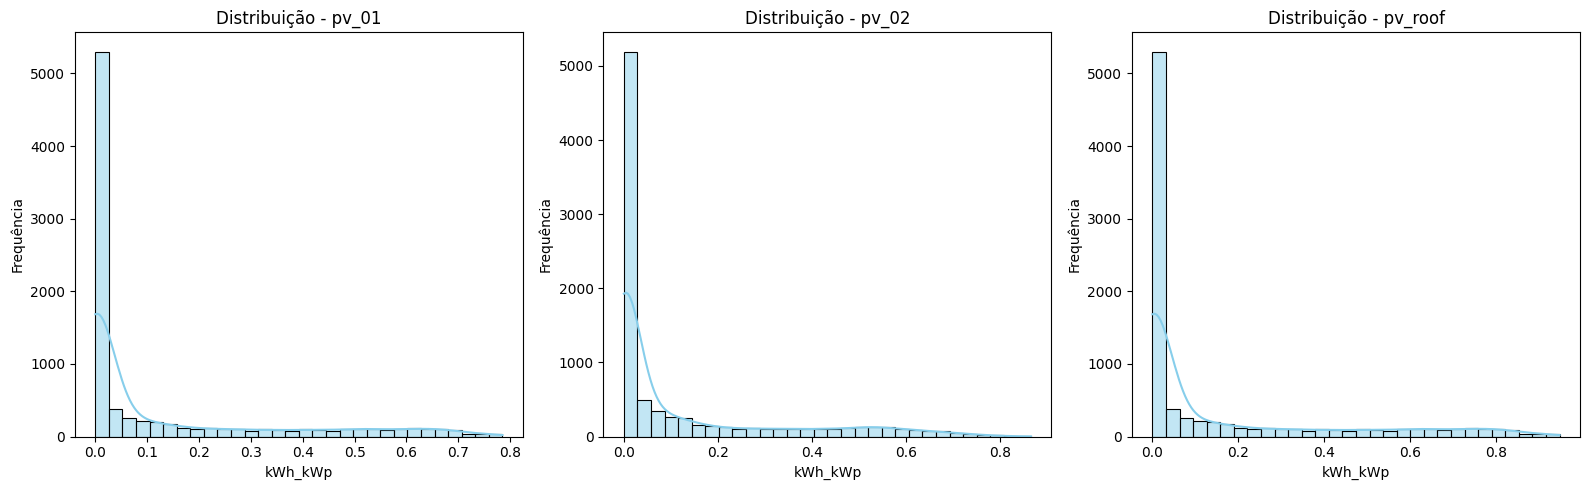

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Garantir que a coluna Datetime está em formato de data/hora
pv_geral["Datetime"] = pd.to_datetime(pv_geral["Datetime"])

colunas_producao = ["pv_01", "pv_02", "pv_roof"]

# --- 2. GRÁFICOS DE DISTRIBUIÇÃO (Histogramas / KDE) ---
plt.figure(figsize=(16, 5))

for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    # Filtramos valores > 0 opcionalmente para focar na produção efetiva, 
    # mas aqui usamos todos os dados para ver o retrato completo
    sns.histplot(pv_geral[col], kde=True, bins=30, color='skyblue')
    plt.title(f'Distribuição - {col}')
    plt.xlabel('kWh_kWp')
    plt.ylabel('Frequência')

plt.tight_layout()
plt.savefig("distribuicoes_histogramas.png", dpi=150)
plt.show()


## Valores em Falta ou Inconsistentes
Na análise de valores em falta podemos observar que não existe nenhum valor em falta.
Como valores inconsistentes foram analisados os seguintes fatores:
- valores negativos
- produção à noite(onde temos em consideração as estações do ano)
- ter valores de produção acima de 1,0
- ter valores nulos ao meio dia no verão 
- ter um valor maior que 0 constante por mais de 6 horas

Após esta análise chegamos a 89 casos de produção de energia à noite. Por esse motivo, foi necessário proceder à análise destes para perceber o porquê destes valores, se seriam valores errados ou simplesmente valores fora do comum. Em primeiro lugar identificámos as horas e os meses em que estes foram identificados (sendo idenificados entre abril e agosto todos as 5 da manhã, havendo mais valores nos meses intermédios) e também os valores de energia.

In [60]:
# --- 1. Contar valores em falta por coluna (Global) ---
print("--- Número de valores em falta por coluna ---")
print(pv_geral.isnull().sum())

--- Número de valores em falta por coluna ---
pv_01       0
pv_02       0
pv_roof     0
Datetime    0
dtype: int64


In [ ]:
pv_geral["Datetime"] = pd.to_datetime(pv_geral["Datetime"])
pv_geral = pv_geral.sort_values("Datetime").reset_index(drop=True)

problemas = []

def registar(mask, serie, motivo):
    sub = pv_geral.loc[mask, ["Datetime", serie]].copy()
    sub["serie"] = serie
    sub["motivo"] = motivo
    sub = sub.rename(columns={serie: "valor"})
    problemas.append(sub)

hora = pv_geral["Datetime"].dt.hour
noite = hora.isin([21, 22, 23, 0, 1, 2, 3, 4, 5])      # janela segura de noite
meio_dia = hora.isin([10, 11, 12, 13, 14])
mes_sol = pv_geral["Datetime"].dt.month.isin([5, 6, 7, 8, 9])

SERIES = ["pv_01", "pv_02", "pv_roof"]

for s in SERIES:
    v = pv_geral[s]
    registar(v < 0, s, "negativo")
    registar(noite & (v > 0.01), s, "produção à noite")
    registar(v > 1.0, s, "acima de 1,0")
    # zeros ao meio-dia em meses de sol (suspeito, não certo)
    registar(meio_dia & mes_sol & (v == 0), s, "zero ao meio-dia no verão (suspeito)")

# timestamps
dup = pv_geral["Datetime"].duplicated(keep=False)
registar(dup, SERIES[0], "timestamp duplicado")

# buracos: horas em falta
esperado = pd.date_range(pv_geral["Datetime"].min(), pv_geral["Datetime"].max(), freq="h")
em_falta = esperado.difference(pv_geral["Datetime"])
print("Horas em falta:", len(em_falta))
print(em_falta[:20])

# séries repetidas / constantes
print("pv_01 == pv_roof ?", pv_geral["pv_01"].equals(pv_geral["pv_roof"]))
for s in SERIES:
    corridas = (pv_geral[s] != pv_geral[s].shift()).cumsum()
    tamanho = pv_geral.groupby(corridas)[s].transform("size")
    registar((tamanho >= 6) & (pv_geral[s] > 0), s, "valor constante >0 durante 6+ horas")

res = pd.concat(problemas).sort_values(["serie", "Datetime"])

# Tabela: tipo de erro (linhas) x coluna (colunas)
motivos_todos = [
    "negativo",
    "produção à noite",
    "acima de 1,0",
    "zero ao meio-dia no verão",
    "valor constante >0 durante 6+ horas",
]

tabela = (res.groupby(["motivo", "serie"]).size()
            .unstack(fill_value=0)
            .reindex(index=motivos_todos, columns=SERIES, fill_value=0))

print(tabela.to_string())

res.to_csv("valores_impossiveis.csv", index=False)
print('')
print("\n--- Primeiras 10 linhas do DataFrame de problemas ---")
print(res.head(10))

Horas em falta: 0
DatetimeIndex([], dtype='datetime64[us]', freq='h')
pv_01 == pv_roof ? False
serie                                pv_01  pv_02  pv_roof
motivo                                                    
negativo                                 0      0        0
produção à noite                         0     89        0
acima de 1,0                             0      0        0
zero ao meio-dia no verão                0      0        0
valor constante >0 durante 6+ horas      0      0        0


--- Primeiras 10 linhas do DataFrame de problemas ---
                Datetime     valor  serie            motivo
2621 2019-04-20 05:00:00  0.010407  pv_02  produção à noite
2645 2019-04-21 05:00:00  0.011057  pv_02  produção à noite
2669 2019-04-22 05:00:00  0.015285  pv_02  produção à noite
2693 2019-04-23 05:00:00  0.012033  pv_02  produção à noite
2741 2019-04-25 05:00:00  0.014959  pv_02  produção à noite
2765 2019-04-26 05:00:00  0.016911  pv_02  produção à noite
2789 2019-04-27 

C:\Users\adria\AppData\Local\Temp\ipykernel_36056\2922681724.py:9: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  res["dia_ano"] = res["Datetime"].dt.dayofyear


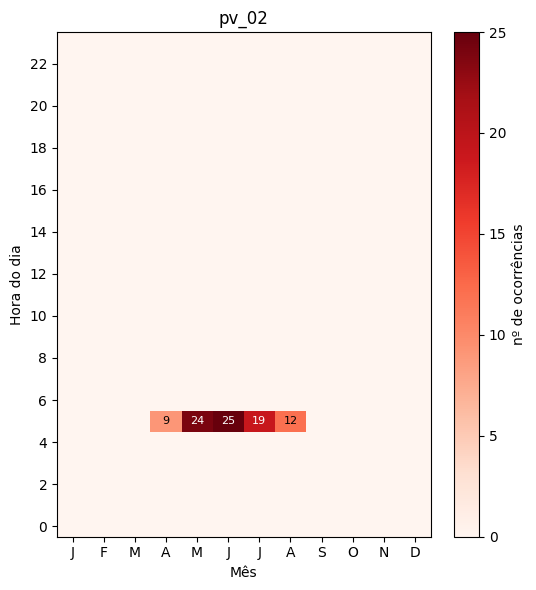

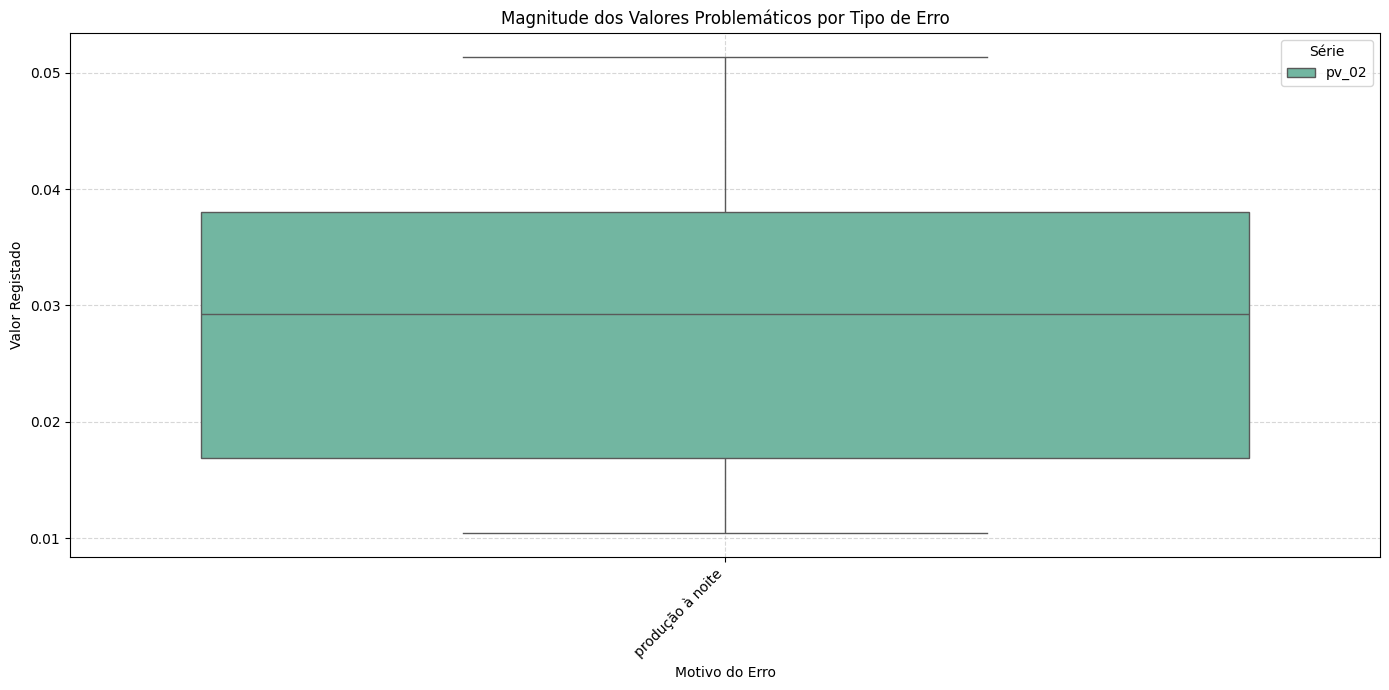

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

res = pd.read_csv("valores_impossiveis.csv", parse_dates=["Datetime"])
res["hora"] = res["Datetime"].dt.hour
res["mes"] = res["Datetime"].dt.month
res["dia_ano"] = res["Datetime"].dt.dayofyear

# Verão = abril a setembro; Inverno = outubro a março
res["estacao"] = np.where(res["mes"].between(4, 9), "Verão (abr–set)", "Inverno (out–mar)")

series = sorted(res["serie"].unique())
motivos = sorted(res["motivo"].unique())
cores = dict(zip(motivos, plt.cm.tab10.colors))

# ---------- 2) Mapa de calor: hora (y) vs mês (x), contagem com valores impressos ----------
fig, axs = plt.subplots(1, len(series), figsize=(5.5 * len(series), 6),
                        sharey=True, squeeze=False)

for ax, s in zip(axs[0], series):
    m = (res[res["serie"] == s]
         .pivot_table(index="hora", columns="mes", values="valor", aggfunc="size", fill_value=0)
         .reindex(index=range(24), columns=range(1, 13), fill_value=0))
    
    im = ax.imshow(m.values, aspect="auto", origin="lower", cmap="Reds")
    
    # --- NOVO: Adicionar os valores numéricos em cada célula do mapa de calor ---
    matriz_valores = m.values
    max_val = matriz_valores.max() if matriz_valores.max() > 0 else 1
    
    for i in range(matriz_valores.shape[0]):      # Linhas (horas)
        for j in range(matriz_valores.shape[1]):  # Colunas (meses)
            val = matriz_valores[i, j]
            if val > 0:  # Opcional: mostrar apenas se for maior que 0 para não poluir
                # Se o fundo for muito escuro, o texto passa a branco
                cor_texto = "white" if val > (max_val * 0.6) else "black"
                ax.text(j, i, str(val), ha="center", va="center", color=cor_texto, fontsize=8)
    # --------------------------------------------------------------------------

    ax.set_xticks(range(12))
    ax.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
    ax.set_yticks(range(0, 24, 2))
    ax.set_title(s)
    ax.set_xlabel("Mês")
    fig.colorbar(im, ax=ax, label="nº de ocorrências")

axs[0, 0].set_ylabel("Hora do dia")
fig.tight_layout()
fig.savefig("impossiveis_heatmap.png", dpi=150)

# ---------- 3) Novo Gráfico: Magnitude dos Valores Anómalos por Motivo e Série ----------
plt.figure(figsize=(14, 7))

# Criamos um boxplot para ver a distribuição dos valores problemáticos
sns.boxplot(
    data=res, 
    x="motivo", 
    y="valor", 
    hue="serie", 
    palette="Set2"
)

plt.xticks(rotation=45, ha="right")
plt.title("Magnitude dos Valores Problemáticos por Tipo de Erro")
plt.xlabel("Motivo do Erro")
plt.ylabel("Valor Registado")
plt.legend(title="Série")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("magnitude_erros_boxplot.png", dpi=150)

plt.show()

## Evolução da produção fotovoltaica ao longo do tempo

Após esta análise concluí-se o que já se previa. Existe uma maior produção em meses de mais exposição solar (verão), e que nas horas de pico de solar (entre as 11 horas e as 14 horas)

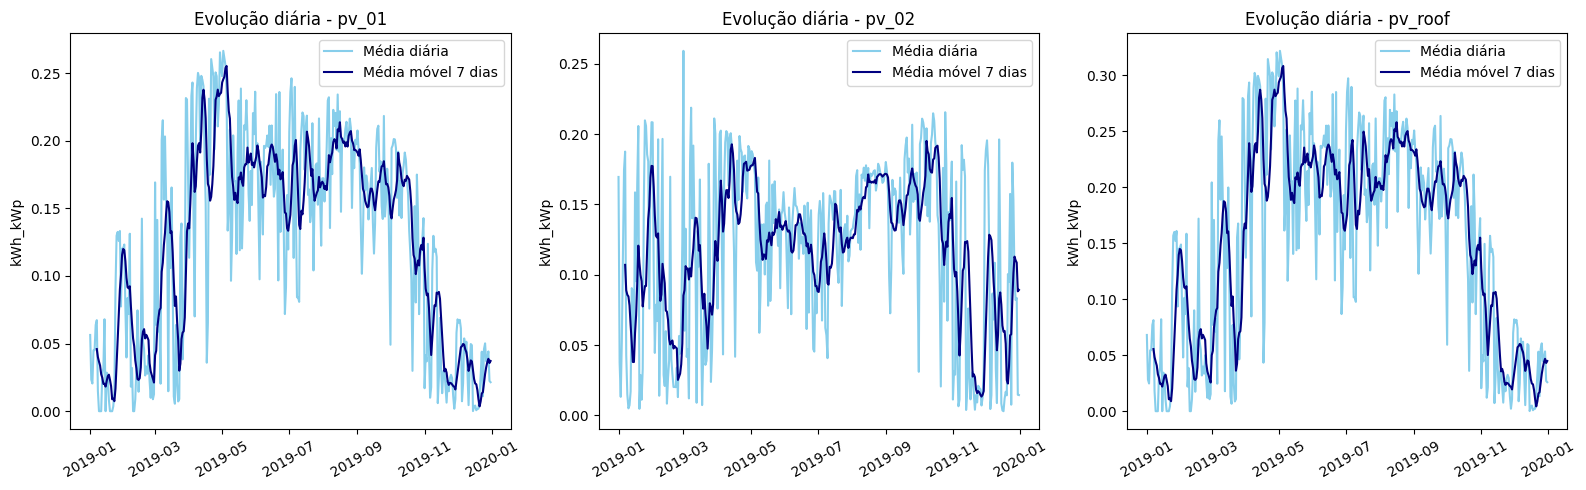

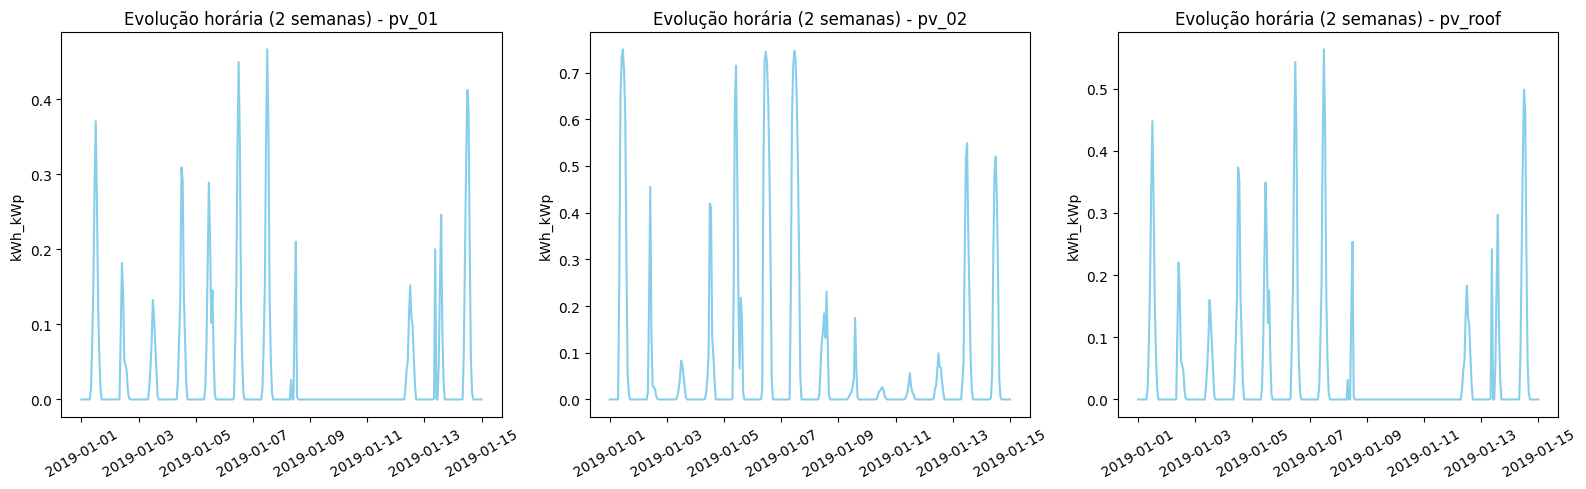

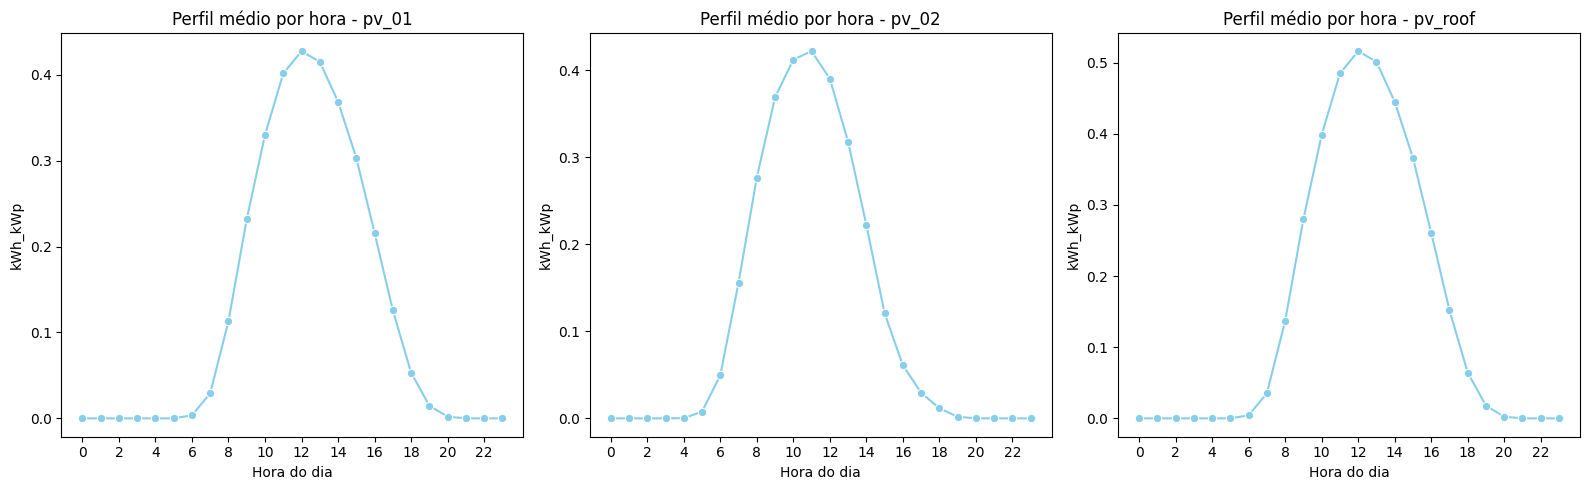

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pv_geral["Datetime"] = pd.to_datetime(pv_geral["Datetime"])
pv_idx = pv_geral.set_index("Datetime").sort_index()

colunas_producao = ["pv_01", "pv_02", "pv_roof"]

# --- 1. EVOLUÇÃO DIÁRIA (média diária + média móvel 7 dias) ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    diario = pv_idx[col].resample("D").mean()
    sns.lineplot(x=diario.index, y=diario.values, label="Média diária", color="skyblue")
    sns.lineplot(x=diario.index, y=diario.rolling(7).mean().values,
                 label="Média móvel 7 dias", color="navy")
    plt.title(f"Evolução diária - {col}")
    plt.xlabel("")
    plt.ylabel("kWh_kWp")
    plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("evolucao_diaria.png", dpi=150)
plt.show()

# --- 2. EVOLUÇÃO HORÁRIA (primeiras 2 semanas, para ficar legível) ---
inicio = pv_idx.index.min()
janela = pv_idx.loc[inicio : inicio + pd.Timedelta(days=14)]

plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    sns.lineplot(x=janela.index, y=janela[col].values, color="skyblue")
    plt.title(f"Evolução horária (2 semanas) - {col}")
    plt.xlabel("")
    plt.ylabel("kWh_kWp")
    plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("evolucao_horaria.png", dpi=150)
plt.show()

# --- 3. PERFIL MÉDIO POR HORA DO DIA (0-23h) ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    perfil = pv_idx[col].groupby(pv_idx.index.hour).mean()
    sns.lineplot(x=perfil.index, y=perfil.values, marker="o", color="skyblue")
    plt.title(f"Perfil médio por hora - {col}")
    plt.xlabel("Hora do dia")
    plt.ylabel("kWh_kWp")
    plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig("perfil_horario.png", dpi=150)
plt.show()

## Padrões diários, semanais e sazonais, quando identificáveis

Novamente com esta análise verificou-se os padrões sazonais, que as estações mais quentes têm mais produção. A nível semanal podemos notar um padrão entre parques que considero enganoso, pois isso não significa nada em concreto, todos são analisados nos mesmos dias e isso faz com que a média por dia de semana tenha mais ou menos sempre a mesma produção, mas não significa que um dia produz mais que outro. Por meses nota-se novamente 

C:\Users\adria\AppData\Local\Temp\ipykernel_36056\4220925211.py:6: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  pv_idx["dia_semana"] = pv_idx.index.dayofweek      # 0 = segunda


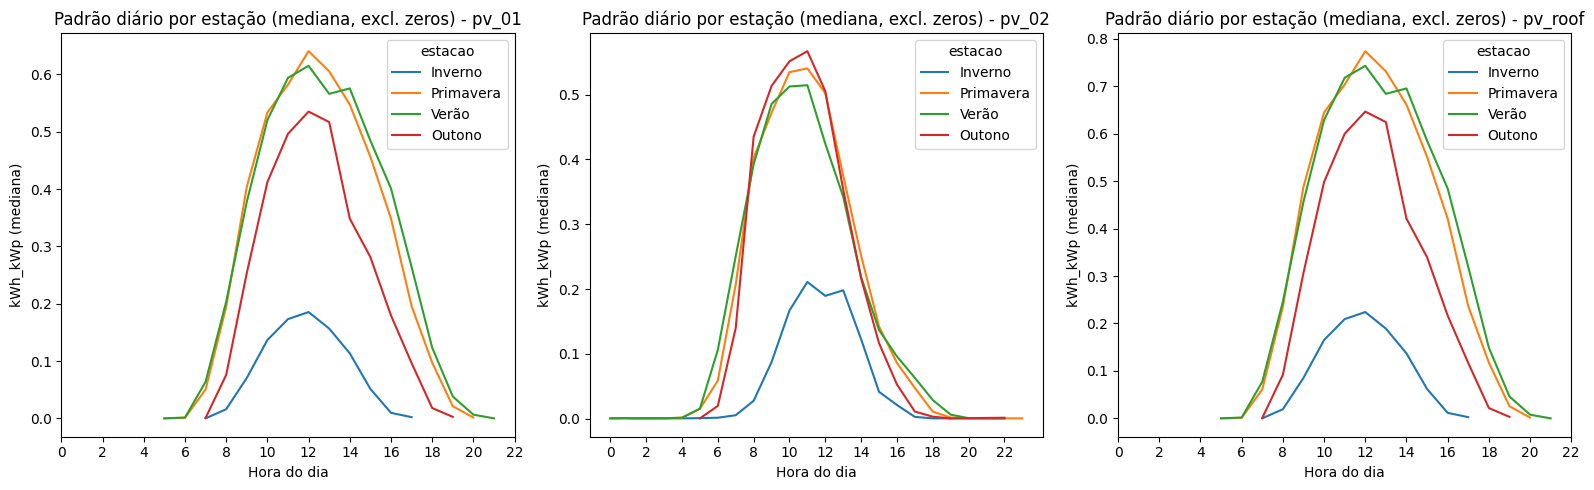

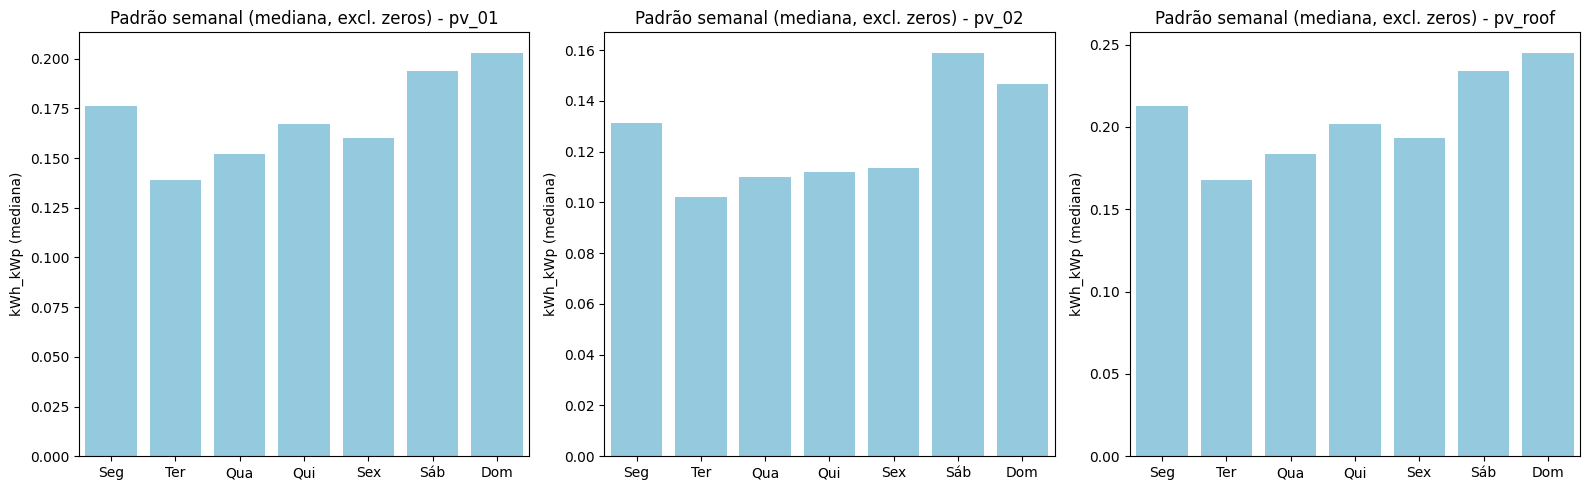

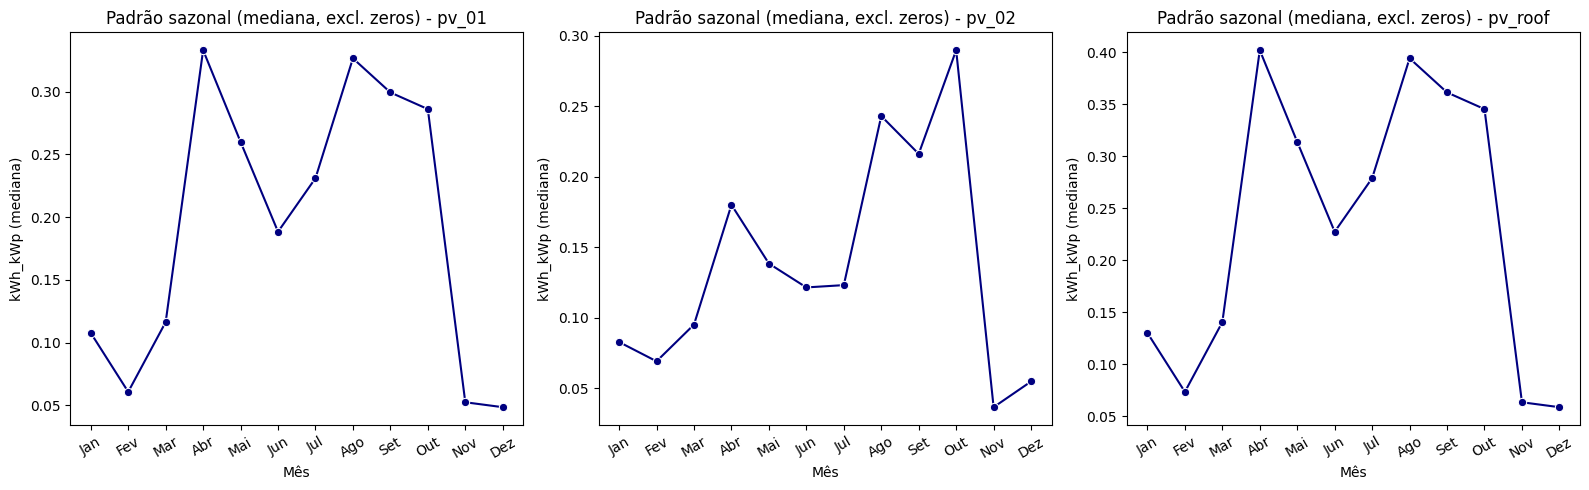

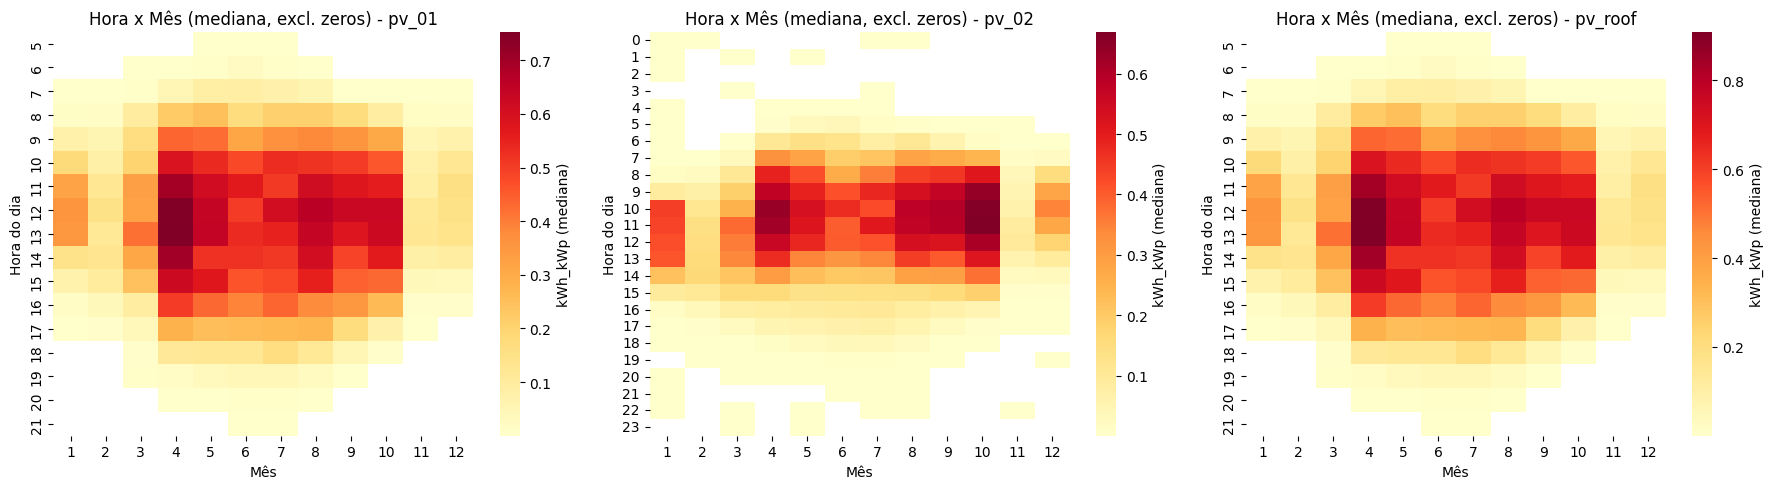

In [68]:


pv_idx = pv_geral.set_index("Datetime").sort_index()
colunas_producao = ["pv_01", "pv_02", "pv_roof"]

# Variáveis temporais auxiliares
pv_idx["hora"] = pv_idx.index.hour
pv_idx["dia_semana"] = pv_idx.index.dayofweek      # 0 = segunda
pv_idx["mes"] = pv_idx.index.month

nomes_dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
nomes_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
               "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

def estacao(m):
    return ("Inverno" if m in (12, 1, 2) else
            "Primavera" if m in (3, 4, 5) else
            "Verão" if m in (6, 7, 8) else "Outono")

pv_idx["estacao"] = pv_idx["mes"].map(estacao)

# --- VERSÃO SEM ZEROS (só para análise visual; pv_idx fica intacto) ---
pv_nz = pv_idx.copy()
pv_nz[colunas_producao] = pv_nz[colunas_producao].replace(0, np.nan)

# --- 1. PADRÃO DIÁRIO: mediana por hora, separado por estação ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    perfil = pv_nz.groupby(["estacao", "hora"])[col].median().reset_index()
    sns.lineplot(data=perfil, x="hora", y=col, hue="estacao",
                 hue_order=["Inverno", "Primavera", "Verão", "Outono"])
    plt.title(f"Padrão diário por estação (mediana, excl. zeros) - {col}")
    plt.xlabel("Hora do dia")
    plt.ylabel("kWh_kWp (mediana)")
    plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig("padrao_diario_mediana_sem_zeros.png", dpi=150)
plt.show()

# --- 2. PADRÃO SEMANAL: mediana por dia da semana ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    semanal = pv_nz.groupby("dia_semana")[col].median().reindex(range(7))
    sns.barplot(x=nomes_dias, y=semanal.values, color="skyblue")
    plt.title(f"Padrão semanal (mediana, excl. zeros) - {col}")
    plt.xlabel("")
    plt.ylabel("kWh_kWp (mediana)")
plt.tight_layout()
plt.savefig("padrao_semanal_mediana_sem_zeros.png", dpi=150)
plt.show()

# --- 3. PADRÃO SAZONAL: mediana por mês ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    mensal = pv_nz.groupby("mes")[col].median().reindex(range(1, 13))
    sns.lineplot(x=mensal.index, y=mensal.values, marker="o", color="navy")
    plt.title(f"Padrão sazonal (mediana, excl. zeros) - {col}")
    plt.xlabel("Mês")
    plt.ylabel("kWh_kWp (mediana)")
    plt.xticks(range(1, 13), nomes_meses, rotation=30)
plt.tight_layout()
plt.savefig("padrao_sazonal_mediana_sem_zeros.png", dpi=150)
plt.show()

# --- 4. MAPA DE CALOR hora x mês (mediana) ---
plt.figure(figsize=(18, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    tabela = pv_nz.pivot_table(index="hora", columns="mes", values=col, aggfunc="median")
    sns.heatmap(tabela, cmap="YlOrRd", cbar_kws={"label": "kWh_kWp (mediana)"})
    plt.title(f"Hora x Mês (mediana, excl. zeros) - {col}")
    plt.xlabel("Mês")
    plt.ylabel("Hora do dia")
plt.tight_layout()
plt.savefig("heatmap_hora_mes_mediana_sem_zeros.png", dpi=150)
plt.show()

## Períodos de produção elevado ou reduzido


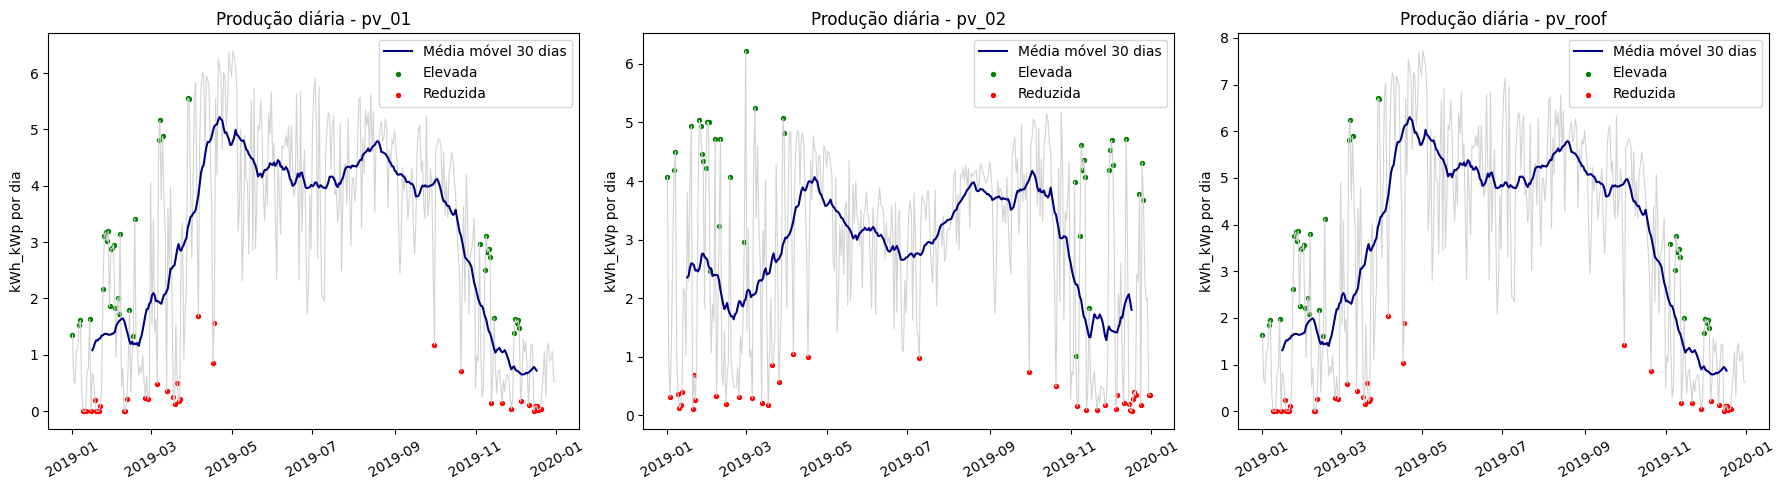

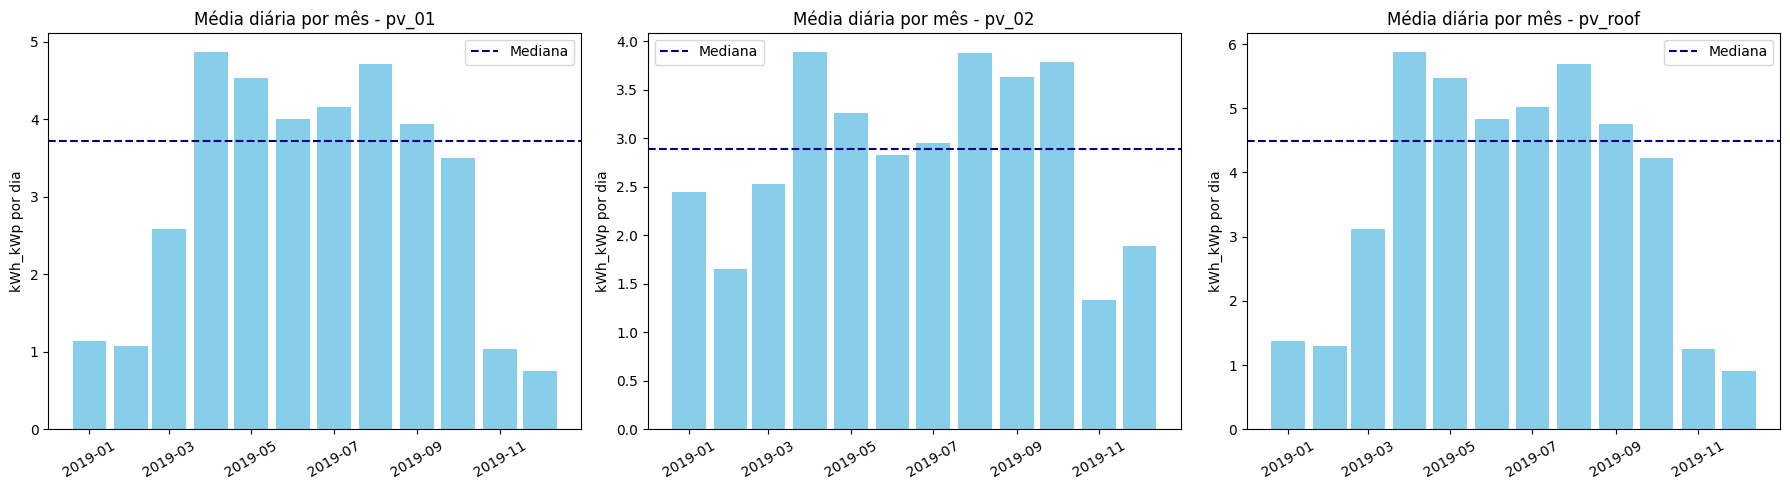


===== pv_01 =====
Períodos REDUZIDOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-12-15 2019-12-20     6
2019-01-18 2019-01-22     5
2019-01-09 2019-01-11     3
2019-02-09 2019-02-11     3
2019-03-21 2019-03-23     3
Períodos ELEVADOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-01-24 2019-02-02    10
2019-11-08 2019-11-12     5
2019-11-30 2019-12-04     5
2019-02-04 2019-02-06     3

===== pv_02 =====
Períodos REDUZIDOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-12-15 2019-12-20     6
2019-01-09 2019-01-12     4
2019-01-20 2019-01-22     3
Períodos ELEVADOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-11-08 2019-11-12     5
2019-01-25 2019-01-28     4
2019-01-30 2019-02-02     4
2019-11-30 2019-12-03     4

===== pv_roof =====
Períodos REDUZIDOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-12-15 2019-12-20     6
2019-01-18 2019-01-22     5
2019-01-09 2019-01-11     3
2019-02-09 2019-02-11     3
2019-03-21 2019-03-23     3
Períodos E

In [69]:
colunas_producao = ["pv_01", "pv_02", "pv_roof"]

# Total diário (com zeros). min_count=1 -> dias sem dados ficam NaN em vez de 0
diario = pv_idx[colunas_producao].resample("D").sum(min_count=1)

# Produção relativa à mediana do mesmo mês (remove a sazonalidade)
ref_mes = diario.groupby(diario.index.month).transform("median")
rel = diario / ref_mes

# Limiares: 10% piores e 10% melhores dias (ajusta 0.10 / 0.90 se quiseres)
p_baixo, p_alto = rel.quantile(0.10), rel.quantile(0.90)

# --- 1. TOTAL DIÁRIO com dias elevados (verde) e reduzidos (vermelho) ---
plt.figure(figsize=(18, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    alto = rel[col] >= p_alto[col]
    baixo = rel[col] <= p_baixo[col]
    plt.plot(diario.index, diario[col], color="lightgray", lw=0.8)
    plt.plot(diario.index, diario[col].rolling(30, center=True).mean(),
             color="navy", lw=1.5, label="Média móvel 30 dias")
    plt.scatter(diario.index[alto], diario[col][alto], s=8, color="green", label="Elevada")
    plt.scatter(diario.index[baixo], diario[col][baixo], s=8, color="red", label="Reduzida")
    plt.title(f"Produção diária - {col}")
    plt.ylabel("kWh_kWp por dia")
    plt.xticks(rotation=30)
    plt.legend()
plt.tight_layout()
plt.savefig("periodos_producao_diaria.png", dpi=150)
plt.show()

# --- 2. PRODUÇÃO MÉDIA DIÁRIA POR MÊS (cada mês de cada ano) ---
mensal = diario.resample("MS").mean()
plt.figure(figsize=(18, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    plt.bar(mensal.index, mensal[col], width=25, color="skyblue")
    plt.axhline(mensal[col].median(), color="navy", ls="--", label="Mediana")
    plt.title(f"Média diária por mês - {col}")
    plt.ylabel("kWh_kWp por dia")
    plt.xticks(rotation=30)
    plt.legend()
plt.tight_layout()
plt.savefig("periodos_producao_mensal.png", dpi=150)
plt.show()

# --- 3. SEQUÊNCIAS DE DIAS CONSECUTIVOS ELEVADOS / REDUZIDOS ---
def sequencias(mask, min_dias=3):
    grupos = (mask != mask.shift()).cumsum()
    out = []
    for _, g in mask.groupby(grupos):
        if g.iloc[0] and len(g) >= min_dias:
            out.append((g.index[0].date(), g.index[-1].date(), len(g)))
    return (pd.DataFrame(out, columns=["inicio", "fim", "dias"])
            .sort_values("dias", ascending=False).head(10))

for col in colunas_producao:
    print(f"\n===== {col} =====")
    print("Períodos REDUZIDOS (>= 3 dias seguidos):")
    print(sequencias(rel[col] <= p_baixo[col]).to_string(index=False))
    print("Períodos ELEVADOS (>= 3 dias seguidos):")
    print(sequencias(rel[col] >= p_alto[col]).to_string(index=False))

# --- 4. TOP 5 MELHORES E PIORES MESES ---
for col in colunas_producao:
    m = mensal[col].dropna().sort_values()
    print(f"\n{col} - 5 meses mais fracos:\n{m.head(5).round(3)}")
    print(f"{col} - 5 meses mais fortes:\n{m.tail(5).round(3)}")

## Outliers

Neste tipo de dataset é complicado de analisar os outliers visto que temos variáveis com muitos zeros e também podemos ter os casos de dias mais ou menos nublados. Então a solução encontrada é agrupar os dados por mês, data e hora, para que consigamos fazer a análise de dados por grupos que façam sentido, conseguindo então "ignorar" os zeros.

Vão ser aplicados então três métodos diferentes para conseguir definir melhor os outliers:

- 1º Método: comparar todas as horas iguais de todos os dias do ano
- 2º Método: comparar por parques de geração, ou seja comparar o rácio entre parques
- 3º Método: comparar os totais diários, ou seja se para o mês que é aquele total faz sentido ou não

### Preparação
Agrupar por mês, data e hora

In [53]:
SERIES = ["pv_01", "pv_02", "pv_roof"]
outliers = pv_geral.set_index("Datetime")[SERIES].copy()
outliers["hora"] = outliers.index.hour
outliers["mes"] = outliers.index.month
outliers["data"] = outliers.index.date

outliers = []

In [ ]:


def mad_z(x):
    med = x.median()
    mad = (x - med).abs().median()
    return 0.6745 * (x - med) / mad if mad > 0 else pd.Series(0, index=x.index)

# ---------- 1) Por hora e mês (só horas com produção) ----------
for s in SERIES:
    dia = outliers[outliers[s] > 0.02]                     # ignora noite e crepúsculo
    z = dia.groupby(["mes", "hora"])[s].transform(mad_z)
    sub = dia.loc[z.abs() > 3.5, [s]].copy()
    sub["z"] = z[z.abs() > 3.5]
    sub["serie"] = s
    sub["metodo"] = "1) fora do típico da hora/mês"
    outliers.append(sub.rename(columns={s: "valor"}))

# ---------- 2) Entre séries (o mais fiável: mesmo local, mesmo sol) ----------
for s in SERIES:
    outras = [c for c in SERIES if c != s]
    ref = outliers[outras].mean(axis=1)
    m = (outliers[s] > 0.05) & (ref > 0.05)          # só quando ambos produzem
    ratio = (outliers.loc[m, s] / ref[m])
    z = ratio.groupby(outliers.loc[m, "mes"]).transform(mad_z)
    sub = outliers.loc[m[m].index[z.abs() > 3.5], [s]].copy()
    sub["z"] = z[z.abs() > 3.5]
    sub["serie"] = s
    sub["metodo"] = "2) desvio face às outras séries"
    outliers.append(sub.rename(columns={s: "valor"}))

# ---------- 3) Totais diários ----------
diario = outliers.groupby("data")[SERIES].sum()
diario.index = pd.to_datetime(diario.index)
for s in SERIES:
    z = diario[s].groupby(diario.index.month).transform(mad_z)
    sub = diario.loc[z.abs() > 3.5, [s]].copy()
    sub["z"] = z[z.abs() > 3.5]
    sub["serie"] = s
    sub["metodo"] = "3) total diário atípico"
    outliers.append(sub.rename(columns={s: "valor"}))

out = pd.concat(outliers)
out.index.name = "Datetime"          # dá nome à coluna da data
out = out.sort_values(["serie", "metodo", "Datetime"])

print(out.groupby(["serie", "metodo"]).size().unstack(fill_value=0))


m1 = out[out["metodo"].str.startswith("1")].reset_index().set_index(["Datetime", "serie"]).index
m2 = out[out["metodo"].str.startswith("2")].reset_index().set_index(["Datetime", "serie"]).index
print(m1.intersection(m2))
out.to_csv("outliers.csv")

metodo   1) fora do típico da hora/mês  2) desvio face às outras séries  \
serie                                                                     
pv_01                              184                               17   
pv_02                              276                              196   
pv_roof                            181                               21   

metodo   3) total diário atípico  
serie                             
pv_01                         11  
pv_02                         22  
pv_roof                       11  
MultiIndex([('2019-02-06 09:00:00',   'pv_01'),
            ('2019-02-17 08:00:00',   'pv_01'),
            ('2019-02-01 08:00:00',   'pv_02'),
            ('2019-02-01 09:00:00',   'pv_02'),
            ('2019-02-06 08:00:00',   'pv_02'),
            ('2019-02-06 09:00:00',   'pv_02'),
            ('2019-02-17 08:00:00',   'pv_02'),
            ('2019-03-29 08:00:00',   'pv_02'),
            ('2019-03-30 08:00:00',   'pv_02'),
            ('201

In [54]:
# dias marcados pelo método 3
dias_m3 = out[out["metodo"].str.startswith("3")].reset_index()
dias_m3["dia"] = pd.to_datetime(dias_m3["Datetime"]).dt.normalize()
dias_m3 = set(zip(dias_m3["dia"], dias_m3["serie"]))

confirmados = m1.intersection(m2)

niveis = []
for dt, s in confirmados:
    dt = pd.Timestamp(dt)
    nivel = "alta" if (dt.normalize(), s) in dias_m3 else "confirmado"
    niveis.append(dict(Datetime=dt, serie=s, nivel=nivel, valor=df.loc[dt, s]))

niveis = pd.DataFrame(niveis).sort_values(["serie", "Datetime"])
print(niveis.groupby(["serie", "nivel"]).size().unstack(fill_value=0))
niveis.to_csv("outliers_por_nivel.csv", index=False)

nivel    alta  confirmado
serie                    
pv_01       1           1
pv_02      13           7
pv_roof     1           0


In [52]:
comuns = m1.intersection(m2)
tip = df.groupby(["mes", "hora"])[SERIES].median()

linhas = []
for dt, s in comuns:
    dt = pd.Timestamp(dt)
    outras = [c for c in SERIES if c != s]
    v = df.loc[dt, s]
    ref = df.loc[dt, outras].mean()
    tipico = tip.loc[(dt.month, dt.hour), s]
    linhas.append(dict(
        Datetime=dt, serie=s, valor=v, media_outras=ref,
        ratio_vs_outras=v / ref if ref > 0 else np.nan,
        tipico_hora_mes=tipico,
        vezes_tipico=v / tipico if tipico > 0 else np.nan,
    ))

tab = pd.DataFrame(linhas).sort_values(["serie", "Datetime"])
print(tab.round(3).to_string(index=False))
tab.to_csv("outliers_confirmados.csv", index=False)

           Datetime   serie  valor  media_outras  ratio_vs_outras  tipico_hora_mes  vezes_tipico
2019-02-06 09:00:00   pv_01  0.282         0.478            0.590            0.045         6.216
2019-02-17 08:00:00   pv_01  0.142         0.314            0.452            0.016         9.093
2019-02-01 08:00:00   pv_02  0.377         0.057            6.629            0.024        15.755
2019-02-01 09:00:00   pv_02  0.656         0.051           12.858            0.072         9.147
2019-02-06 08:00:00   pv_02  0.257         0.065            3.927            0.024        10.762
2019-02-06 09:00:00   pv_02  0.616         0.311            1.979            0.072         8.594
2019-02-17 08:00:00   pv_02  0.457         0.157            2.915            0.024        19.129
2019-03-29 08:00:00   pv_02  0.545         0.219            2.486            0.105         5.170
2019-03-30 08:00:00   pv_02  0.517         0.151            3.435            0.105         4.910
2019-04-05 08:00:00   pv_02  0

C:\Users\adria\AppData\Local\Temp\ipykernel_36056\2017359777.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(tab.round(3).to_string(index=False))
